# Codveda Data Science Internship — Level 2 (Intermediate)

This notebook covers **Task 1: Predictive Modeling (Regression)**, **Task 2: Classification with Logistic Regression**, and, as a bonus, **Task 3: Clustering (Customer Segmentation)** — only 2 of the 3 are required, but the churn dataset fit Task 3's own example ("customer segmentation") too well to skip.

- Task 1 uses the **Boston Housing dataset** to predict house price (MEDV)
- Task 2 uses the **Iris dataset** to predict species
- Task 3 uses the **BigML Telecom Churn dataset** to segment customers

## Task 1: Predictive Modeling (Regression)

Predict median house value (`MEDV`) from the Boston Housing features.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Create the column names for the Boston Housing dataset.
columns = ["CRIM","ZN","INDUS","CHAS","NOX","RM","AGE","DIS","RAD",
           "TAX","PTRATIO","B","LSTAT","MEDV"]

# Load the Boston Housing dataset from the CSV file. # sep=r"\s+" means the values are separated by spaces.
# header=None means the original file does not contain column names.
# names=columns assigns the column names created above.
df = pd.read_csv("4) house Prediction Data Set.csv",
                  sep=r"\s+", header=None, names=columns)

X = df.drop(columns=["MEDV"])
y = df["MEDV"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (404, 13), Test size: (102, 13)


In [2]:
# Create three different regression models.
models = {
    # Linear Regression assumes a mainly linear relationship between features and price.
    "Linear Regression": LinearRegression(),
    # Decision Tree learns prediction rules by splitting the data into smaller groups.
    "Decision Tree": DecisionTreeRegressor(random_state=42, max_depth=6),
    # Random Forest combines many decision trees to improve prediction performance.
    "Random Forest": RandomForestRegressor(random_state=42, n_estimators=200, max_depth=10),
}
# Create an empty list to store the evaluation results of each model.
results = []
# Create a dictionary to store the predictions made by each model.
predictions = {}

# Loop through every model in the models dictionary.
for name, model in models.items():
    # Train the current model using the training data.
    model.fit(X_train, y_train)
    # Use the trained model to predict house prices for the test data.
    preds = model.predict(X_test)
    # Save the predictions so we can use them later for visualization.
    predictions[name] = preds
    # Calculate Mean Squared Error.
    # Lower MSE means the predictions are closer to the actual values.
    mse = mean_squared_error(y_test, preds)
    rmse = mse ** 0.5
    # Calculate R-squared.
    # A higher R2 means the model explains more of the variation in house prices.
    r2 = r2_score(y_test, preds)
    # Store the model name and its evaluation scores.
    results.append({"Model": name, "MSE": round(mse, 2), "RMSE": round(rmse, 2), "R2": round(r2, 3)})

# Convert the results list into a pandas DataFrame.
# Sort the models from highest to lowest R2 score.
results_df = pd.DataFrame(results).sort_values("R2", ascending=False)
print(results_df.to_string(index=False))

            Model   MSE  RMSE    R2
    Random Forest  8.47  2.91 0.884
    Decision Tree  8.93  2.99 0.878
Linear Regression 24.29  4.93 0.669


Best model: Random Forest


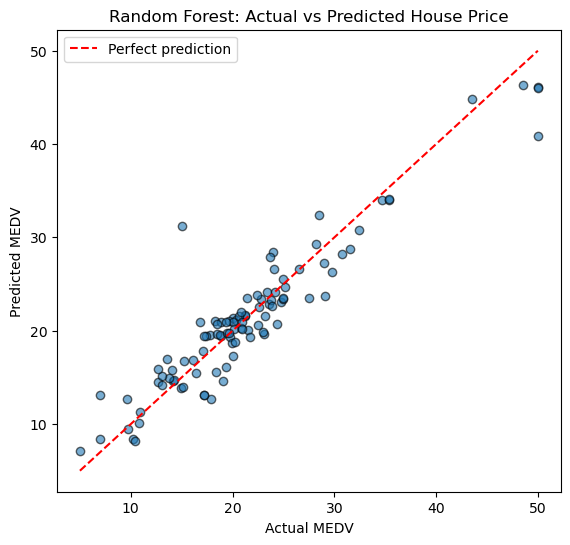

In [3]:
# Select the name of the model with the highest R2 score.
best_name = results_df.iloc[0]["Model"]
# Get the predictions made by the best-performing model.
best_preds = predictions[best_name]
print(f"Best model: {best_name}")

# Create the figure and axes for the scatter plot.
fig, ax = plt.subplots(figsize=(6.5, 6))
# Plot the actual house prices against the predicted house prices.
# Each point represents one house from the test dataset.
ax.scatter(y_test, best_preds, alpha=0.6, edgecolor="k")
# Find the minimum and maximum values needed for the reference line.
lims = [min(y_test.min(), best_preds.min()), max(y_test.max(), best_preds.max())]

# Draw a reference line representing perfect predictions.
# Points close to this line indicate accurate predictions.
ax.plot(lims, lims, "r--", label="Perfect prediction")
ax.set_xlabel("Actual MEDV")
ax.set_ylabel("Predicted MEDV")
ax.set_title(f"{best_name}: Actual vs Predicted House Price")
ax.legend()
plt.show()

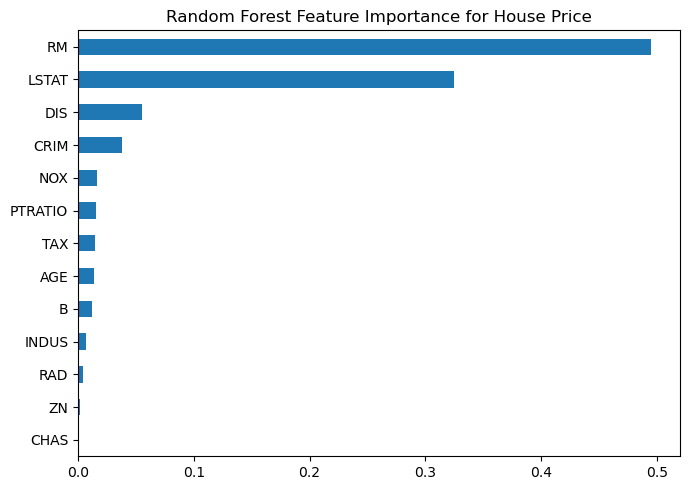

RM         0.495
LSTAT      0.325
DIS        0.055
CRIM       0.038
NOX        0.016
PTRATIO    0.016
TAX        0.015
AGE        0.014
B          0.012
INDUS      0.007
RAD        0.004
ZN         0.002
CHAS       0.001
dtype: float64


In [4]:
# Get the Random Forest model that was already trained above.
rf = models["Random Forest"]

# Get the importance of every feature from the Random Forest.
# Higher values mean the feature contributed more to the model's predictions.
importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

# Create the figure and axes for the feature-importance chart.
fig, ax = plt.subplots(figsize=(7, 5))
# Create a horizontal bar chart showing feature importance.
importances.plot(kind="barh", ax=ax)
ax.invert_yaxis() # Reverse the y-axis so the most important feature appears at the top.
ax.set_title("Random Forest Feature Importance for House Price")
plt.tight_layout()
plt.show()
print(importances.round(3))

**Interpretation:** Random Forest and Decision Tree outperform plain Linear Regression, suggesting that the relationship between the features and house prices is not purely linear. `RM` (average number of rooms per dwelling) and `LSTAT` (percentage of lower-status population) are consistently among the strongest predictors of house price.

## Task 2: Classification with Logistic Regression

Predict flower species from the Iris dataset.

In [5]:
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, classification_report, roc_curve, auc
from sklearn.preprocessing import label_binarize

iris = pd.read_csv("1) iris.csv")

# Create Xi containing the flower measurements.
# The species column is removed because it is the target we want to predict.
Xi = iris.drop(columns=["species"])
le = LabelEncoder() # Create a LabelEncoder to convert species names into numbers.
# Convert the species names into numerical labels.
yi = le.fit_transform(iris["species"])
class_names = le.classes_   # Store the original class names.
print("Classes:", list(class_names)) # Display the available classes.


# Split the Iris data into training and testing sets.
# 80% is used for training and 20% for testing.
# stratify=yi keeps the class proportions similar in both sets.
Xi_train, Xi_test, yi_train, yi_test = train_test_split(Xi, yi, test_size=0.2,
                                                          random_state=42, stratify=yi)

# Create a StandardScaler to put the features on a similar scale.
scaler = StandardScaler()
# Learn the scaling values from the training data and transform it.
Xi_train_s = scaler.fit_transform(Xi_train)
# Apply the same scaling learned from the training data to the test data.
Xi_test_s = scaler.transform(Xi_test)

Classes: ['setosa', 'versicolor', 'virginica']


In [6]:
# Create the Logistic Regression model.
# max_iter=500 gives the model enough iterations to find a solution.
logreg = LogisticRegression(max_iter=500)
# Train the Logistic Regression model using the scaled training data.
logreg.fit(Xi_train_s, yi_train)
# Use the trained model to predict the species of the test flowers.
yi_pred = logreg.predict(Xi_test_s)

# Calculate the percentage of predictions that were correct.
acc = accuracy_score(yi_test, yi_pred)
# Calculate macro-average precision across all three flower classes.
prec = precision_score(yi_test, yi_pred, average="macro")
# Calculate macro-average recall across all three flower classes.
rec = recall_score(yi_test, yi_pred, average="macro")
# Display the main classification metrics.
print(f"Logistic Regression -> Accuracy: {acc:.3f}, Precision (macro): {prec:.3f}, Recall (macro): {rec:.3f}")
print()
# Display precision, recall, F1-score, and support for each flower species.
print(classification_report(yi_test, yi_pred, target_names=class_names))

Logistic Regression -> Accuracy: 0.933, Precision (macro): 0.933, Recall (macro): 0.933

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



In [7]:
# Compare against other classifiers
# Create several classification models so their performance can be compared.
clf_models = {
    # Logistic Regression is the main classification model.
    "Logistic Regression": LogisticRegression(max_iter=500),
    # Random Forest combines multiple decision trees.
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=200),
    # SVM finds a boundary that separates the different classes.
    "SVM": SVC(probability=True, random_state=42),
}
# Create an empty list to store the comparison results.
comparison = []
# Loop through every classifier.
for name, clf in clf_models.items():
    clf.fit(Xi_train_s, yi_train) # Train the classifier using the scaled training data.
    pred = clf.predict(Xi_test_s) # Predict the classes for the test data.
    
    # Store the evaluation results for the current classifier.
    comparison.append({
        "Model": name,
        "Accuracy": round(accuracy_score(yi_test, pred), 3),# Calculate accuracy.
        # Calculate macro-average precision.
        "Precision": round(precision_score(yi_test, pred, average="macro"), 3),
        # Calculate macro-average recall.
        "Recall": round(recall_score(yi_test, pred, average="macro"), 3),
    })
    # Convert the comparison results into a DataFrame.
    # This makes it easier to compare the models.
pd.DataFrame(comparison)

,Model,Accuracy,Precision,Recall
0,Logistic Regression,0.933,0.933,0.933
1,Random Forest,0.900,0.902,0.900
2,SVM,0.967,0.970,0.967


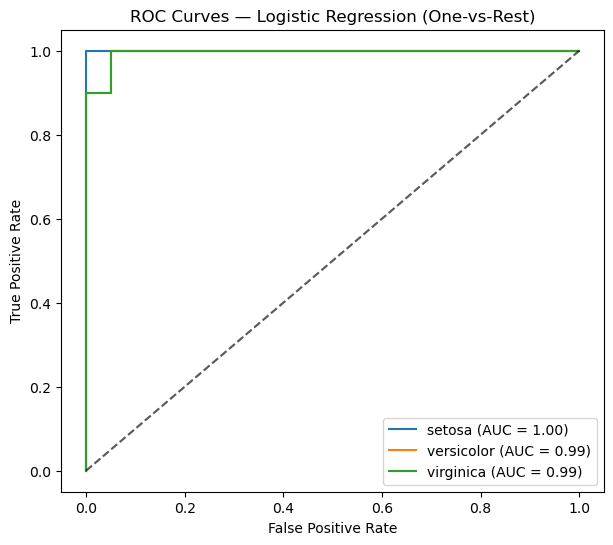

In [8]:
# ROC curves (one-vs-rest) for logistic regression
# Convert the three-class test labels into a binary format.
# This allows us to create one ROC curve for each species.
y_test_bin = label_binarize(yi_test, classes=[0, 1, 2])
# Get the predicted probability for each flower class.
y_score = logreg.predict_proba(Xi_test_s)

# Create the figure and axes for the ROC curves.
fig, ax = plt.subplots(figsize=(7, 6))
# Create one ROC curve for each flower species.
for i, cls in enumerate(class_names):
    # Calculate the false-positive rate and true-positive rate.
    fpr, tpr, _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc = auc(fpr, tpr) # Calculate the Area Under the ROC Curve.
                          # A value closer to 1 means stronger class separation.
    
    # Plot the ROC curve for the current species.
    ax.plot(fpr, tpr, label=f"{cls} (AUC = {roc_auc:.2f})")
ax.plot([0, 1], [0, 1], "k--", alpha=0.4)
ax.plot([0, 1], [0, 1], "k--", alpha=0.4) # Add a diagonal reference line.
                            # This represents random classification performance.

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — Logistic Regression (One-vs-Rest)")
ax.legend()
plt.show()

**Interpretation:** Logistic Regression achieves very high accuracy on Iris  as the Level 1 EDA showed, petal measurements make the species almost linearly separable. Setosa is classified perfectly (AUC = 1.0); any misclassifications, if present, happen between versicolor and virginica, which overlap slightly in feature space.

## Task 3 (Bonus): Clustering — Customer Segmentation

The task list's own example for K-Means clustering is "customer segmentation" and the BigML Telecom Churn dataset (churn-bigml-80.csv / churn-bigml-20.csv) is exactly that: real customer usage data. The internship only requires 2 of the 3 Level 2 tasks, but since this dataset fits Task 3 precisely, it's included here as a bonus third task.

Clustering is unsupervised  the Churn label is dropped before clustering and only brought back afterward to see whether the discovered segments relate to churn behavior.

In [9]:
# Load the training portion of the telecom churn dataset.
churn_train = pd.read_csv("churn-bigml-80.csv")
# Load the testing portion of the telecom churn dataset.
churn_test = pd.read_csv("churn-bigml-20.csv")

# Combine the training and testing files into one dataset.
# Clustering is being used here for customer segmentation,
# so we work with the complete customer dataset.
churn = pd.concat([churn_train, churn_test], ignore_index=True)
# Display the number of rows and columns in the combined dataset.
print("Combined shape:", churn.shape)
# Count all missing values in the dataset.
print("Missing values:", churn.isna().sum().sum())
churn.head()

Combined shape: (3333, 20)
Missing values: 0


,State,Account length,Area code,International plan,Voice mail plan,Number vmail messages,Total day minutes,Total day calls,Total day charge,Total eve minutes,Total eve calls,Total eve charge,Total night minutes,Total night calls,Total night charge,Total intl minutes,Total intl calls,Total intl charge,Customer service calls,Churn
0,KS,128,415,No,Yes,25,265.1,110,45.07,197.4,99,16.78,244.7,91,11.01,10.0,3,2.70,1,False
1,OH,107,415,No,Yes,26,161.6,123,27.47,195.5,103,16.62,254.4,103,11.45,13.7,3,3.70,1,False
2,NJ,137,415,No,No,0,243.4,114,41.38,121.2,110,10.30,162.6,104,7.32,12.2,5,3.29,0,False
3,OH,84,408,Yes,No,0,299.4,71,50.90,61.9,88,5.26,196.9,89,8.86,6.6,7,1.78,2,False
4,OK,75,415,Yes,No,0,166.7,113,28.34,148.3,122,12.61,186.9,121,8.41,10.1,3,2.73,3,False


In [10]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

# Keep the actual churn label separate.
# The churn label must not be given to K-Means because clustering is unsupervised.
churn_label = churn["Churn"].astype(bool)

# Remove the target label and location-based columns.
# State and Area code are removed because this segmentation focuses on customer behavior.
cluster_df = churn.drop(columns=["Churn", "State", "Area code"]).copy()
# Convert the International plan column from Yes/No into 1/0.
cluster_df["International plan"] = (cluster_df["International plan"] == "Yes").astype(int)
# Convert the Voice mail plan column from Yes/No into 1/0.
cluster_df["Voice mail plan"] = (cluster_df["Voice mail plan"] == "Yes").astype(int)

# Create a StandardScaler to put all clustering features on a similar scale.
scaler3 = StandardScaler()
# Standardize the clustering features.
cluster_scaled = scaler3.fit_transform(cluster_df)
# Display the number of customers and features being used for clustering.
print("Feature matrix for clustering:", cluster_scaled.shape)
# Display the names of the features used by K-Means.
print("Features used:", list(cluster_df.columns))

Feature matrix for clustering: (3333, 17)
Features used: ['Account length', 'International plan', 'Voice mail plan', 'Number vmail messages', 'Total day minutes', 'Total day calls', 'Total day charge', 'Total eve minutes', 'Total eve calls', 'Total eve charge', 'Total night minutes', 'Total night calls', 'Total night charge', 'Total intl minutes', 'Total intl calls', 'Total intl charge', 'Customer service calls']


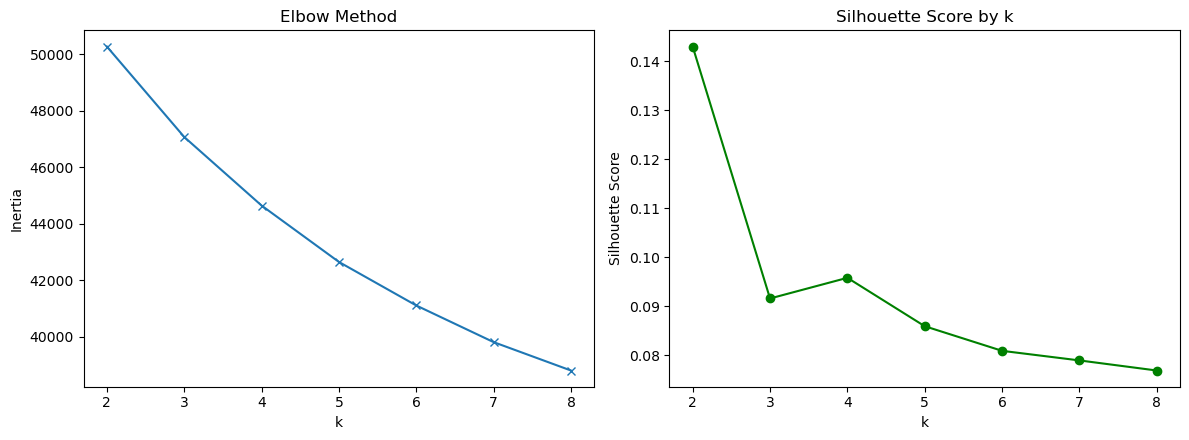

k=2: silhouette=0.143
k=3: silhouette=0.092
k=4: silhouette=0.096
k=5: silhouette=0.086
k=6: silhouette=0.081
k=7: silhouette=0.079
k=8: silhouette=0.077


In [11]:
# Elbow method + silhouette score to pick k
# Create empty lists to store the evaluation results.
inertias, sil_scores = [], []

k_range = range(2, 9) # Test different numbers of clusters from 2 through 8.
for k in k_range:       # Test every possible value of k.
    # Create a K-Means model with the current number of clusters.
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    # Train K-Means and assign every customer to a cluster.
    labels_k = km.fit_predict(cluster_scaled)
    
    # Calculate and store the silhouette score.
    # A higher silhouette score generally indicates better-separated clusters.
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(cluster_scaled, labels_k))

# Create two plots side by side.
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# Plot the inertia values for the Elbow Method.
axes[0].plot(list(k_range), inertias, marker="x")
axes[0].set_xlabel("k"); axes[0].set_ylabel("Inertia"); axes[0].set_title("Elbow Method")

# Plot the silhouette score for each value of k.
axes[1].plot(list(k_range), sil_scores, marker="o", color="green")
axes[1].set_xlabel("k"); axes[1].set_ylabel("Silhouette Score"); axes[1].set_title("Silhouette Score by k")
plt.tight_layout()
plt.show()

# Print the silhouette score for every tested value of k.
for k, s in zip(k_range, sil_scores):
    print(f"k={k}: silhouette={s:.3f}")

In [12]:
# Find the value of k with the highest silhouette score.
best_k = list(k_range)[int(np.argmax(sil_scores))]
# Display the selected number of clusters.
print(f"Chosen k (highest silhouette score): {best_k}")

# Create the final K-Means model using the selected number of clusters.
kmeans_final = KMeans(n_clusters=best_k, random_state=42, n_init=10)
# Train K-Means and assign each customer to a cluster.
cluster_labels = kmeans_final.fit_predict(cluster_scaled)
# Add the cluster assignment back to the customer dataset.
churn["Cluster"] = cluster_labels

Chosen k (highest silhouette score): 2


Explained variance (2 PCs): 24.04%


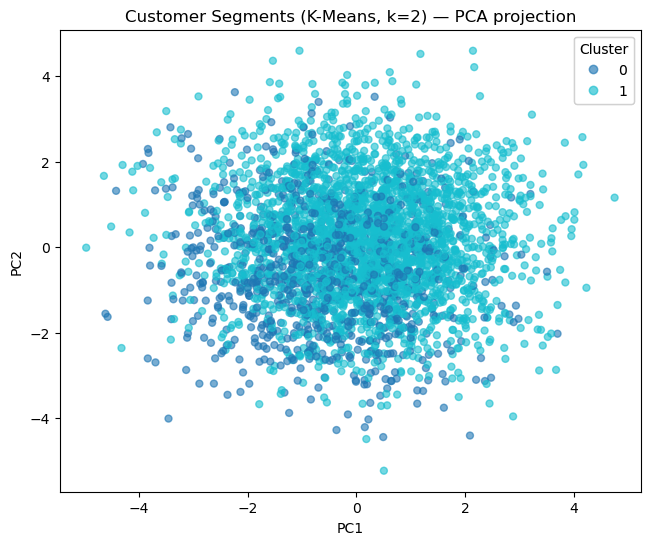

In [13]:

# Reduce all clustering features to 2 principal components
# so that the high-dimensional customer data can be visualized in 2D.
pca = PCA(n_components=2, random_state=42)

# Transform the scaled clustering data into the two principal components.
# PC1 and PC2 contain the main patterns of variation in the customer data.
coords = pca.fit_transform(cluster_scaled)

# Show how much of the total data variation is captured by the two components.
print(f"Explained variance (2 PCs): {pca.explained_variance_ratio_.sum():.2%}")

# Create the figure and axes for the scatter plot.
fig, ax = plt.subplots(figsize=(7.5, 6))

# Plot each customer using PC1 on the x-axis and PC2 on the y-axis.
# The color of each point represents the K-Means cluster assigned to that customer.
scatter = ax.scatter(
    coords[:, 0],
    coords[:, 1],
    c=cluster_labels,
    cmap="tab10",
    alpha=0.6,
    s=25
)

# Label the two principal-component axes.
ax.set_xlabel("PC1")
ax.set_ylabel("PC2")

# Add a title showing that the plot is a PCA projection of the K-Means clusters.
ax.set_title(f"Customer Segments (K-Means, k={best_k}) — PCA projection")

# Create a legend so each color can be matched to its cluster number.
legend1 = ax.legend(
    *scatter.legend_elements(),
    title="Cluster",
    loc="best"
)

# Add the cluster legend to the plot.
ax.add_artist(legend1)

# Display the completed scatter plot.
plt.show()




### Scatter Plot — PCA Visualization of Customer Segments

The scatter plot shows the customer segments created by K-Means after reducing the multiple clustering features to two principal components using PCA. Each point represents one customer, and the different colors represent the K-Means cluster assigned to that customer.

**PC1** and **PC2** summarize the main patterns of variation in the customer usage data, allowing the high-dimensional dataset to be viewed in two dimensions. Customers that appear closer together in the plot have more similar overall usage patterns, while customers farther apart have more different patterns.

The clusters may overlap in this two-dimensional projection because K-Means was performed using multiple features, not just PC1 and PC2. Therefore, the scatter plot provides a visual representation of the segments rather than the complete separation used to create the clusters.



In [14]:
# Interpret clusters: profile + churn rate per segment
# Create a numerical version of the International plan column.
# Yes becomes 1 and No becomes 0.
churn["Intl plan (num)"] = (churn["International plan"] == "Yes").astype(int)
# Create a numerical version of the Voice mail plan column.
# Yes becomes 1 and No becomes 0.
churn["Voicemail plan (num)"] = (churn["Voice mail plan"] == "Yes").astype(int)

# Select the customer features we want to use when describing each cluster.
profile_cols = ["Account length", "Total day minutes", "Total eve minutes",
                 "Total night minutes", "Total intl minutes", "Customer service calls",
                 "Intl plan (num)", "Voicemail plan (num)"]
# Calculate the average value of each selected feature for every cluster.
profile = churn.groupby("Cluster")[profile_cols].mean().round(2)
# Count how many customers belong to each cluster.
profile["Segment size"] = churn.groupby("Cluster").size()

# Calculate the churn rate for each cluster.
# The churn label was kept separate earlier so K-Means did not use it.
profile["Churn rate"] = churn.groupby("Cluster").apply(lambda g: churn_label.loc[g.index].mean(), include_groups=False).round(3)
# Sort the clusters from highest churn rate to lowest churn rate.
profile = profile.sort_values("Churn rate", ascending=False)
profile            # Display the final cluster profile table.

,Account length,Total day minutes,Total eve minutes,Total night minutes,Total intl minutes,Customer service calls,Intl plan (num),Voicemail plan (num),Segment size,Churn rate
Cluster,,,,,,,,,,
1,100.99,179.83,200.30,200.68,10.24,1.58,0.1,0.0,2411,0.167
0,101.25,179.63,202.75,201.37,10.23,1.52,0.1,1.0,922,0.087


In [15]:
# Select the first row because the profile is sorted by churn rate.
# This represents the segment with the highest churn rate.
overall_rate = churn_label.mean()
highest = profile.iloc[0]

# Select the last row because the profile is sorted by churn rate.
# This represents the segment with the lowest churn rate.
lowest = profile.iloc[-1]
# Display the overall churn rate.
print(f"Overall churn rate: {overall_rate:.1%}")
# Display the highest-churn segment and its size.
print(f"Highest-risk segment: Cluster {profile.index[0]} -> {highest['Churn rate']:.1%} churn "
      f"({int(highest['Segment size'])} customers)")
# Display the lowest-churn segment and its size.
print(f"Lowest-risk segment:  Cluster {profile.index[-1]} -> {lowest['Churn rate']:.1%} churn "
      f"({int(lowest['Segment size'])} customers)")
print()
# Add a heading before displaying the feature differences.
print("Highest-risk segment profile vs overall average:")
# Compare the highest-churn segment's average feature values
# with the overall customer averages.
print((profile.iloc[0][profile_cols] - churn[profile_cols].mean()).round(2))

Overall churn rate: 14.5%
Highest-risk segment: Cluster 1 -> 16.7% churn (2411 customers)
Lowest-risk segment:  Cluster 0 -> 8.7% churn (922 customers)

Highest-risk segment profile vs overall average:
Account length           -0.07
Total day minutes         0.05
Total eve minutes        -0.68
Total night minutes      -0.19
Total intl minutes        0.00
Customer service calls    0.02
Intl plan (num)           0.00
Voicemail plan (num)     -0.28
dtype: float64



**Interpretation:** K-Means identifies behaviorally distinct customer segments purely from usage patterns (day/evening/night minutes, service calls, international/voicemail plan usage), without using the `Churn` label. Cross-referencing the segments with the actual `Churn` label afterward (shown above) shows that churn rates vary substantially across segments  some are well above the overall churn rate, while others are well below. This provides an actionable signal for retention teams to identify higher-risk segments rather than treating all customers the same.

